# MSCS 634 Lab 5: Hierarchical and DBSCAN Clustering

**Name:** Urusha Budhathoki

**Course:** MSCS 634 - M50 – Advanced Big Data and Data Mining

**Assignment:** Lab 5 – Clustering Techniques Using DBSCAN and Hierarchical Clustering

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    homogeneity_score,
    completeness_score
)

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Number of samples:", X.shape[0])

Dataset loaded successfully!
Dataset shape: (178, 13)
Number of features: 13
Number of samples: 178


In [3]:
print("First five rows:")
display(X.head())

print("\nDataset information:")
X.info()

print("\nStatistical description:")
display(X.describe())

First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [4]:
print("Missing values in each column:")
print(X.isnull().sum())

print("\nWine class distribution:")
print(pd.Series(y).value_counts())

Missing values in each column:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Wine class distribution:
1    71
0    59
2    48
Name: count, dtype: int64


In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardization completed!")
print("Standardized data shape:", X_scaled.shape)

Standardization completed!
Standardized data shape: (178, 13)


In [6]:
hierarchical_results = {}

for k in [2, 3, 4, 5]:
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(X_scaled)

    hierarchical_results[k] = labels

    silhouette = silhouette_score(X_scaled, labels)
    homogeneity = homogeneity_score(y, labels)
    completeness = completeness_score(y, labels)

    print(f"\nNumber of clusters: {k}")
    print("Silhouette Score:", round(silhouette, 4))
    print("Homogeneity Score:", round(homogeneity, 4))
    print("Completeness Score:", round(completeness, 4))


Number of clusters: 2
Silhouette Score: 0.267
Homogeneity Score: 0.4441
Completeness Score: 0.7745

Number of clusters: 3
Silhouette Score: 0.2774
Homogeneity Score: 0.7904
Completeness Score: 0.7825

Number of clusters: 4
Silhouette Score: 0.2258
Homogeneity Score: 0.7904
Completeness Score: 0.649

Number of clusters: 5
Silhouette Score: 0.1867
Homogeneity Score: 0.8106
Completeness Score: 0.5762


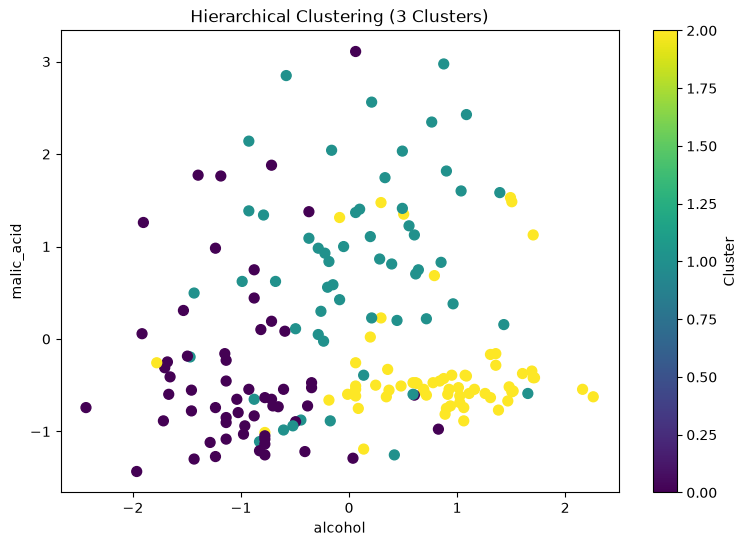

In [7]:
plt.figure(figsize=(9, 6))

labels = hierarchical_results[3]

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap='viridis',
    s=50
)

plt.title("Hierarchical Clustering (3 Clusters)")
plt.xlabel(wine.feature_names[0])
plt.ylabel(wine.feature_names[1])
plt.colorbar(label="Cluster")
plt.show()

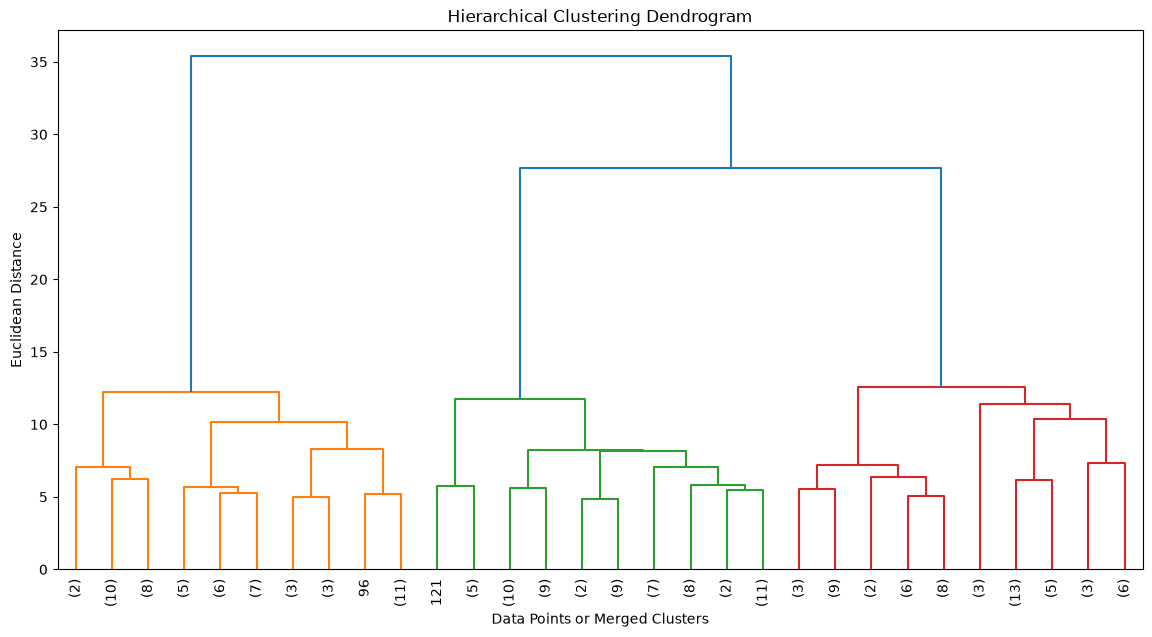

In [8]:
linked = linkage(X_scaled, method='ward')

plt.figure(figsize=(14, 7))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points or Merged Clusters")
plt.ylabel("Euclidean Distance")
plt.show()

The dendrogram graph shows how wine samples are classified
into bigger groups depending on similarities among them.
Vertical distances show dissimilarity between clusters formed.
Higher vertical distances can be seen as possible locations
where data can be segmented into distinct clusters.

In [9]:
dbscan_results = {}

parameters = [
    (0.5, 5),
    (1.0, 5),
    (1.5, 5),
    (2.0, 5),
    (2.5, 5)
]

for eps, min_samples in parameters:

    model = DBSCAN(
        eps=eps,
        min_samples=min_samples
    )

    labels = model.fit_predict(X_scaled)

    dbscan_results[(eps, min_samples)] = labels

    unique_labels = set(labels)
    n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
    n_noise = list(labels).count(-1)

    print(f"\neps={eps}, min_samples={min_samples}")
    print("Number of clusters:", n_clusters)
    print("Number of noise points:", n_noise)

    if n_clusters > 1:
        print("Silhouette Score:",
              round(silhouette_score(X_scaled, labels), 4))
        print("Homogeneity Score:",
              round(homogeneity_score(y, labels), 4))
        print("Completeness Score:",
              round(completeness_score(y, labels), 4))
    else:
        print("Clustering metrics not calculated: fewer than 2 clusters.")


eps=0.5, min_samples=5
Number of clusters: 0
Number of noise points: 178
Clustering metrics not calculated: fewer than 2 clusters.

eps=1.0, min_samples=5
Number of clusters: 0
Number of noise points: 178
Clustering metrics not calculated: fewer than 2 clusters.

eps=1.5, min_samples=5
Number of clusters: 0
Number of noise points: 178
Clustering metrics not calculated: fewer than 2 clusters.

eps=2.0, min_samples=5
Number of clusters: 5
Number of noise points: 85
Silhouette Score: -0.0329
Homogeneity Score: 0.3624
Completeness Score: 0.3247

eps=2.5, min_samples=5
Number of clusters: 1
Number of noise points: 24
Clustering metrics not calculated: fewer than 2 clusters.


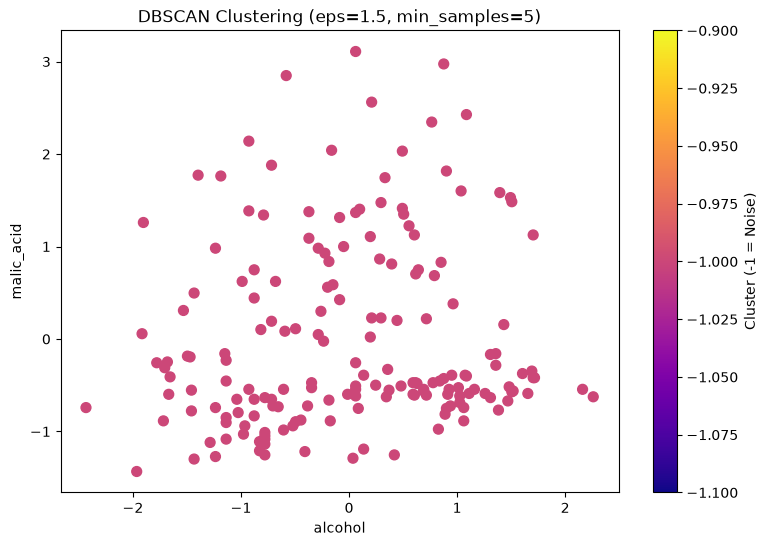

In [10]:
eps = 1.5
min_samples = 5

labels = dbscan_results[(eps, min_samples)]

plt.figure(figsize=(9, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap='plasma',
    s=50
)

plt.title("DBSCAN Clustering (eps=1.5, min_samples=5)")
plt.xlabel(wine.feature_names[0])
plt.ylabel(wine.feature_names[1])
plt.colorbar(label="Cluster (-1 = Noise)")
plt.show()

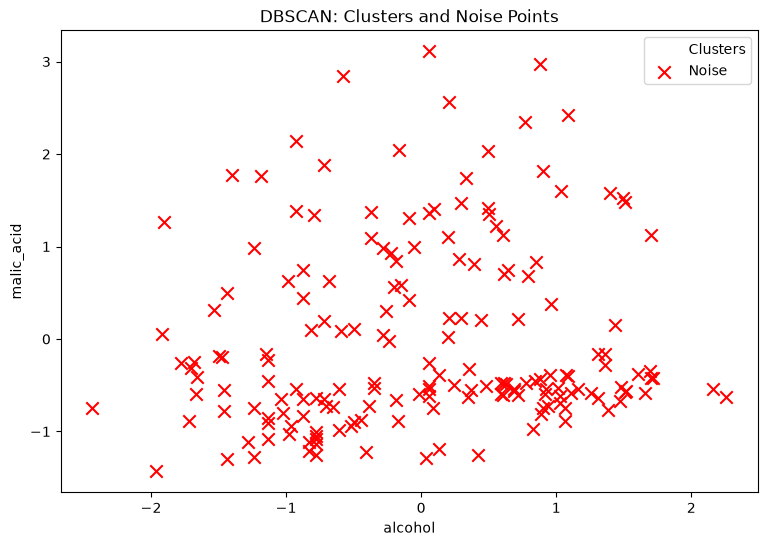

Number of noise points: 178
Number of clustered points: 0


In [11]:
labels = dbscan_results[(1.5, 5)]

noise = labels == -1
clusters = ~noise

plt.figure(figsize=(9, 6))

plt.scatter(
    X_scaled[clusters, 0],
    X_scaled[clusters, 1],
    c=labels[clusters],
    cmap='viridis',
    s=50,
    label='Clusters'
)

plt.scatter(
    X_scaled[noise, 0],
    X_scaled[noise, 1],
    color='red',
    marker='x',
    s=80,
    label='Noise'
)

plt.title("DBSCAN: Clusters and Noise Points")
plt.xlabel(wine.feature_names[0])
plt.ylabel(wine.feature_names[1])
plt.legend()
plt.show()

print("Number of noise points:", sum(noise))
print("Number of clustered points:", sum(clusters))

In [12]:
comparison = []

# Hierarchical clustering results
for k, labels in hierarchical_results.items():
    comparison.append({
        "Algorithm": "Hierarchical",
        "Parameters": f"n_clusters={k}",
        "Silhouette": silhouette_score(X_scaled, labels),
        "Homogeneity": homogeneity_score(y, labels),
        "Completeness": completeness_score(y, labels)
    })

# DBSCAN results
for (eps, min_samples), labels in dbscan_results.items():

    unique_labels = set(labels)
    n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)

    if 1 < n_clusters < len(labels):
        comparison.append({
            "Algorithm": "DBSCAN",
            "Parameters": f"eps={eps}, min_samples={min_samples}",
            "Silhouette": silhouette_score(X_scaled, labels),
            "Homogeneity": homogeneity_score(y, labels),
            "Completeness": completeness_score(y, labels)
        })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Algorithm,Parameters,Silhouette,Homogeneity,Completeness
0,Hierarchical,n_clusters=2,0.2670,0.4441,0.7745
1,Hierarchical,n_clusters=3,0.2774,0.7904,0.7825
2,Hierarchical,n_clusters=4,0.2258,0.7904,0.6490
3,Hierarchical,n_clusters=5,0.1867,0.8106,0.5762
4,DBSCAN,"eps=2.0, min_samples=5",-0.0329,0.3624,0.3247


## Step 4: Analysis and Insights

### Comparison of Hierarchical and DBSCAN Clustering

Cluster analysis through hierarchical clustering and DBSCAN
is done using different strategies. Cluster formation through
hierarchical clustering is based on distances between points,
whereas DBSCAN relies on the density of data points.

The ability to vary the number of clusters and visualize
their relationships through a dendrogram was provided by hierarchical
clustering.

I saw how different eps and min_samples affect the process of
cluster formation using DBSCAN.

### Parameter Influence

The number of clusters in hierarchical clustering can be regulated using the n_clusters parameter.

In DBSCAN clustering, eps controls the neighborhood distance, and min_samples controls the number of points required to form a dense region.

Both parameters control the number of clusters and the number of noise points.

### Strengths and Weaknesses

Hierarchical clustering is effective in that its dendrogram
enables one to gain an understanding of how clusters are
related visually. But hierarchical clustering needs one to define
the number of clusters and is computationally intensive for large
data sets.

DBSCAN can detect irregular shapes and
even noise without having to specify the number of clusters
first. But DBSCAN performance is dependent on the parameters
set.

### Conclusion

The purpose of this lab is to help me learn about two unsupervised learning algorithms.
Through this experiment, I learned about the impact of data normalization, parameter tuning, and evaluation metrics on clustering performance.
Moreover, different algorithms can discover different patterns from the same data set.
